# WEEK2: Resampling Methods

# Objective

This homework sheet will help reviewing the basic concepts associated with model selection and regularization. Please review the lectures, suggested readings, and additional resources _before_ getting started on the HW.

**Some questions in this assignment will require you to conduct independent research beyond the material covered in the recorded content.**

**Questions**

 This homework is divided into two main parts. First, a conceptual component will review the basic concepts related to resampling. The second part of the homework is mostly intended to be a brief introduction to regularization methods and resampling in python . Several of these questions are modified from James et al. (2021).

Marks Distribution

| Question      | Marks |
| ----------- | ----------- |
| Q1a    | 1     |
| Q1b    | 0.50      |
| Q1c   | 1      |
| Q1d     | 0.50      |
| Q1e     | 0.50     |
| Q1f    | 0.50    |
| Q2a    | 1     |
| Q2b    | 1      |
| Q2c   | 1      |
| Q2d     | 1      |
| Q3a   | 1    |
| Q3b     | 1      |
| Q4     | 1      |
| Q5a    | 1    |
| Q5b    | 1     |
| Q5c   | 1     |
| Q5d     | 1      |

# Conceptual

##  Q1. We will derive the probability that a given observation is part of a bootstrap sample. Suppose that we obtain a bootstrap sample from a set of `n` observations. **Please note that samples are obtained with replacement**.

### a) What is the probability that the first bootstrap observation is not the $jth$ observation from the original sample? Justify your answer.

Provide your answer in this Markdown cell

### b) What is the probability that the second bootstrap observation is not the $jth$ observation from the original sample?



 Provide your answer in this Markdown cell

###  c) Argue that the probability that the $jth$ observation is not in the bootstrap sample is $(1 − 1/n)^n$.

Provide your answer in this Markdown cell

###  d) When `n = 5`, what is the probability that the $jth$ observation is in the bootstrap sample?

Provide your answer in this Markdown cell

### e) When `n = 100`, what is the probability that the $jth$ observation is in the bootstrap sample?

Provide your answer in this Markdown cell

### f) When `n = 1000`, what is the probability that the $jth$ observation is in the bootstrap sample?


Provide your answer in this Markdown cell


## Q2)
The following questions are relative to k-fold cross-validation.

### a) Explain how k-fold cross-validation is implemented.


Provide your answer in this Markdown cell

### b) How would you choose the analyzed k? Does that matter?

Provide your answer in this Markdown cell


### c) What are the advantages and disadvantages of k-fold cross-validation relative to: *The validation set* approach?


Provide your answer in this Markdown cell

### d)  What are the advantages and disadvantages of k-fold cross-validation relative to: *LOOCV*?

Provide your answer in this Markdown cell

# Applied

We have to use college dataset to answer the questions given in the notebook

## Q3)

### a) What is the following code supposed to do?

In [4]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

# Define constants
N = 100
ORDER = 2
N_FOLDS = 20
POLY_DEGREE = np.arange(1, 11)
N_REPLICATES = 10

# Set random seed for reproducibility
np.random.seed(123)

# Generate simulated data
x = np.random.uniform(low=-4, high=4, size=N)
y = np.random.normal(loc=x**ORDER, scale=0.25, size=N)
data = pd.DataFrame({'x': x, 'y': y})

# Run multiple replicates and average the MSE estimates
mse_estimates = np.zeros((N_REPLICATES, len(POLY_DEGREE)))
for r in range(N_REPLICATES):
    kf = KFold(n_splits=N_FOLDS, shuffle=True)
    indices = [(train_index, test_index) for train_index, test_index in kf.split(data)]
    for q_idx, q in enumerate(POLY_DEGREE):
        y_hat = np.zeros(N)
        for train_index, test_index in indices:
            # Fit on K-1 folds
            x_train, y_train = data.iloc[train_index]['x'], data.iloc[train_index]['y']
            poly = PolynomialFeatures(degree=q)
            x_train_poly = poly.fit_transform(x_train.reshape(-1, 1))
            lin_reg = LinearRegression()
            lin_reg.fit(x_train_poly, y_train)

            # Predict on the kth fold
            x_test = data.iloc[test_index]['x']
            x_test_poly = poly.fit_transform(x_test.reshape(-1, 1))
            y_hat[test_index] = lin_reg.predict(x_test_poly)

        # Get the MSE estimate
        mse_estimate = np.mean((y_hat - data['y'])**2)
        mse_estimates[r, q_idx] = mse_estimate

# Average the MSE estimates across replicates
mse_mean = np.mean(mse_estimates, axis=0)
mse_std = np.std(mse_estimates, axis=0)

Looking in indexes: https://nexus.corp.indeed.com/repository/pypi/simple
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 18.5 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.2/302.2 kB 13.7 MB/s eta 0:00:00


AttributeError: 'Series' object has no attribute 'reshape'

Provide your answer in this Markdown cell

 ### b) To the best of your knowledge, improve the structure, content, clarity, and reproducibility of the code presented before in "part a" of this question (e.g. would you run a single or multiple replicates?). Fix any mistakes (if you find any). Finally, generate at least two plots summarizing your findings regarding the best-fitting polynomial order on the simulated dataset (also from "part a"): (1) MSE vs polynomial order, and (2) x vs y, along with a plot of the selected model.

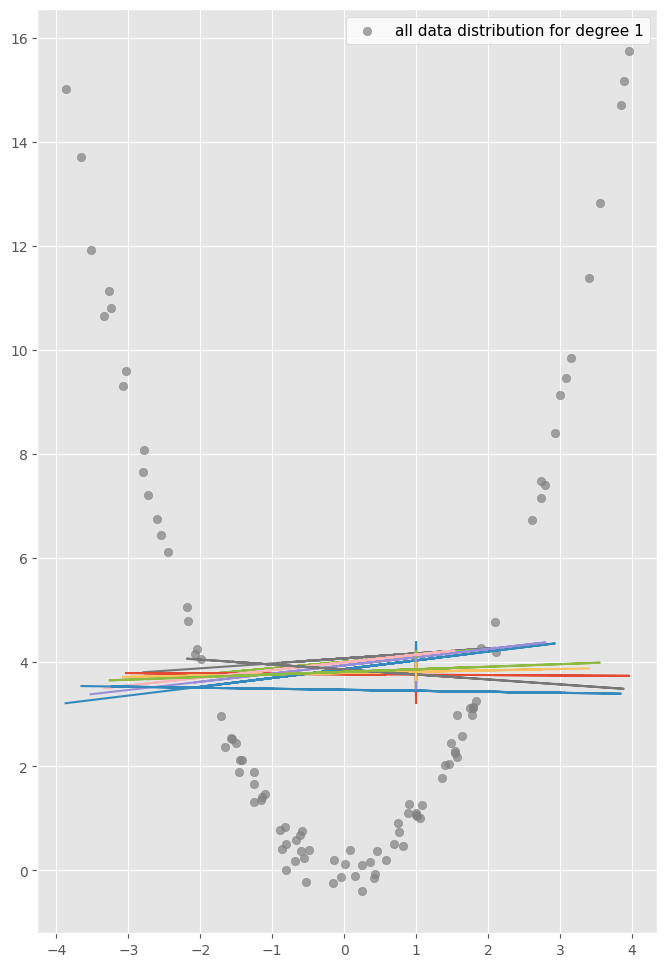

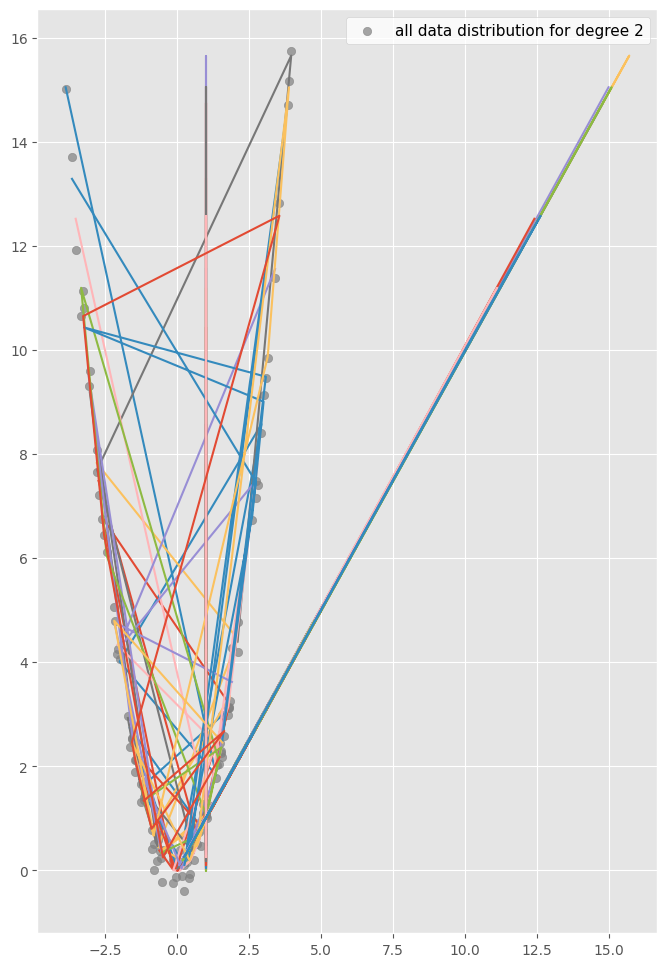

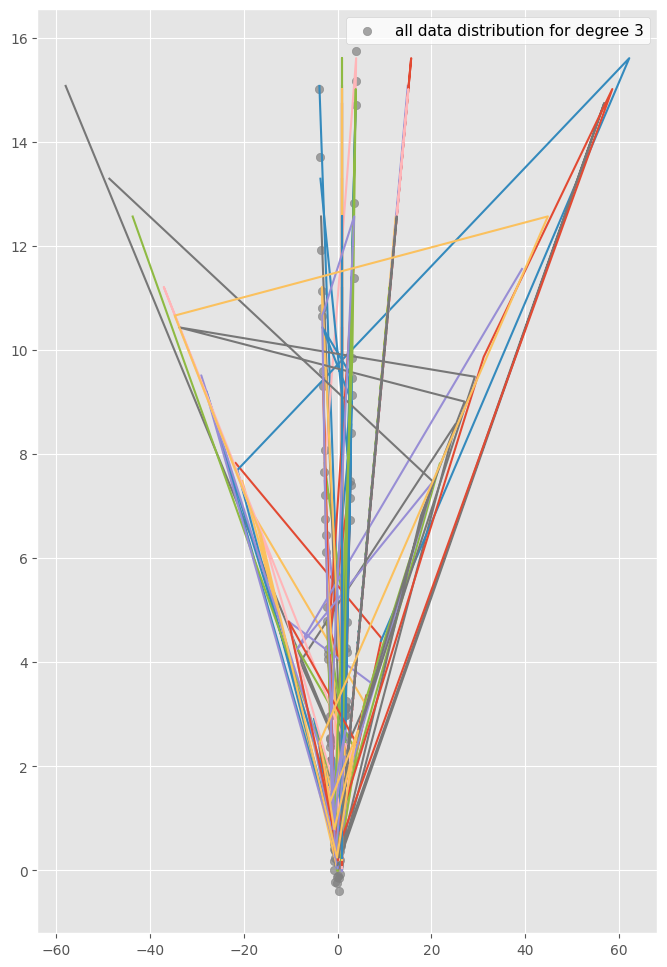

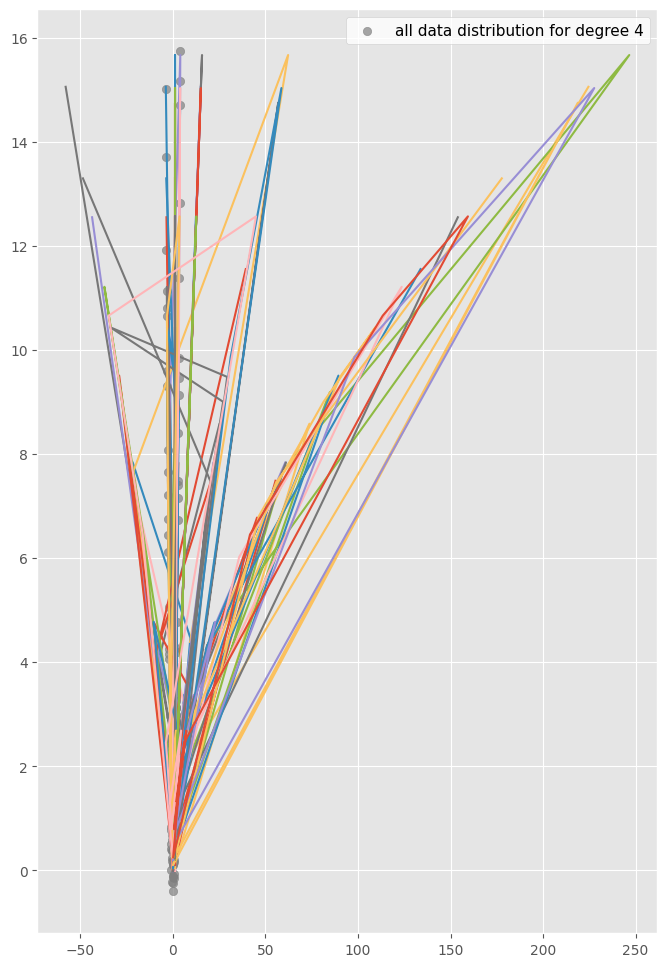

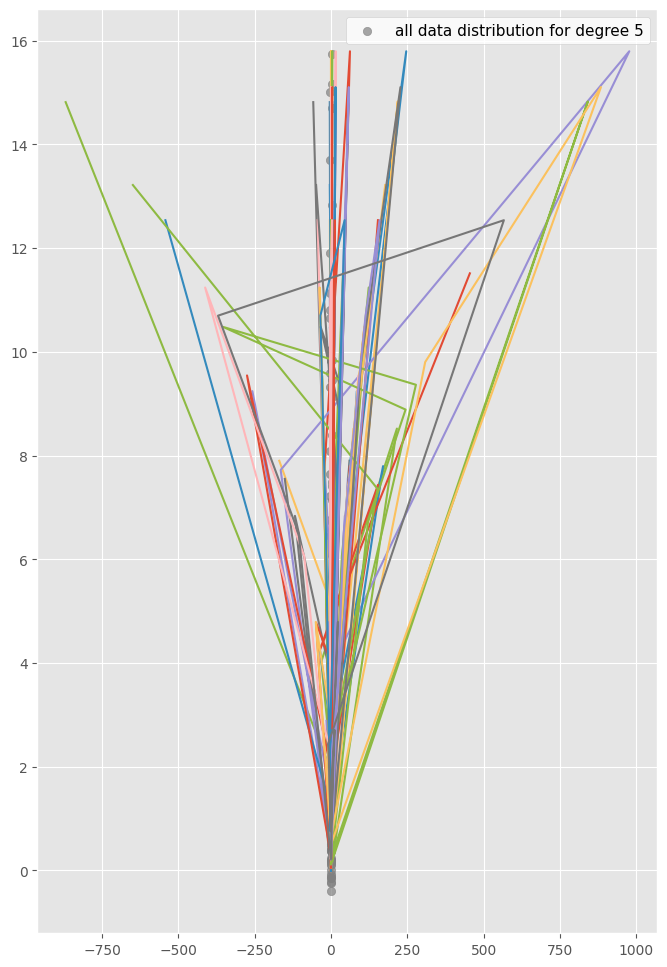

...

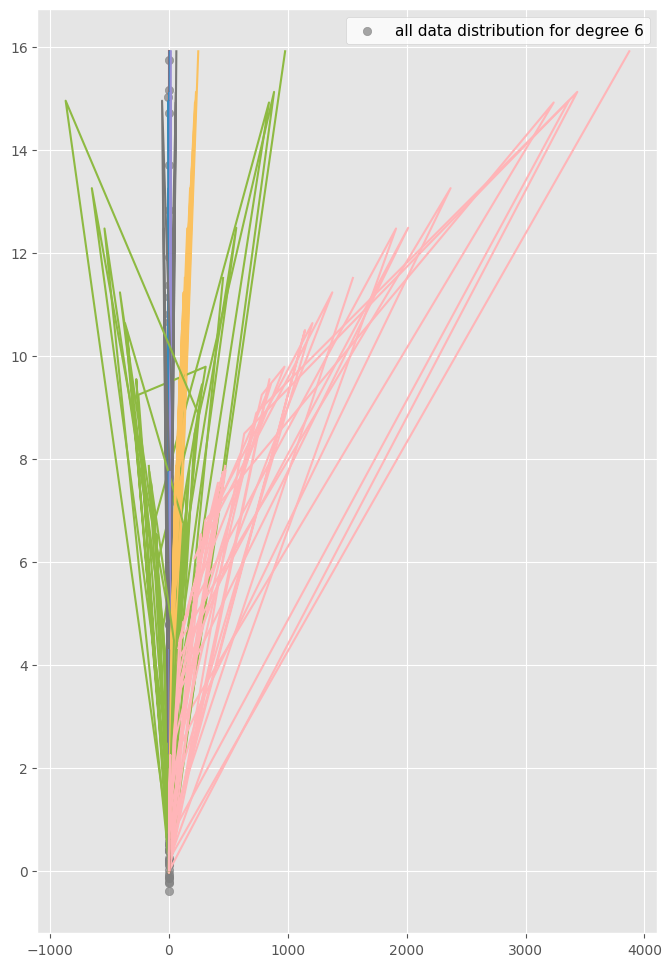

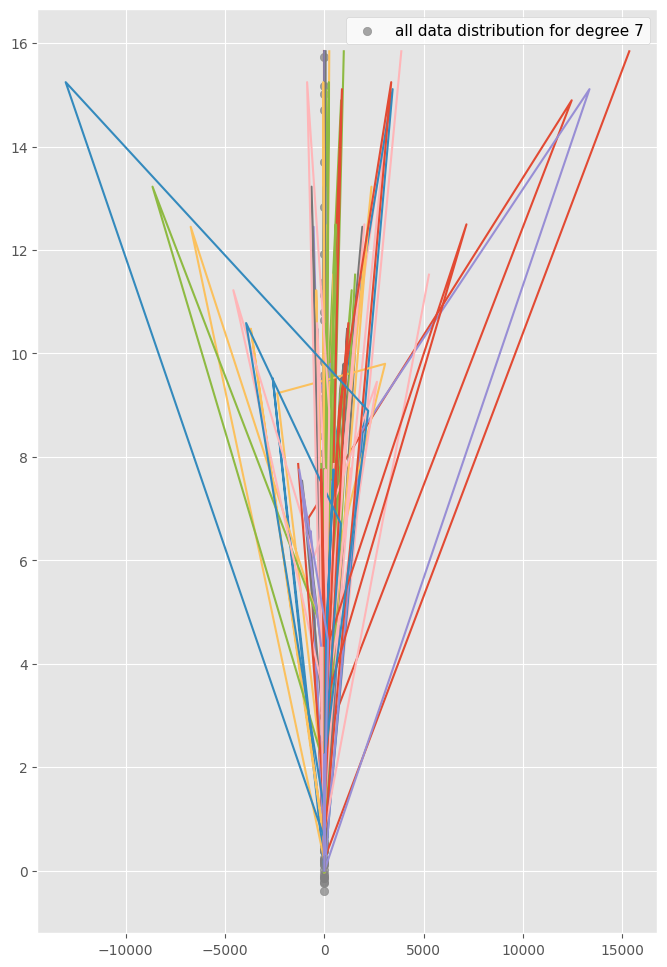

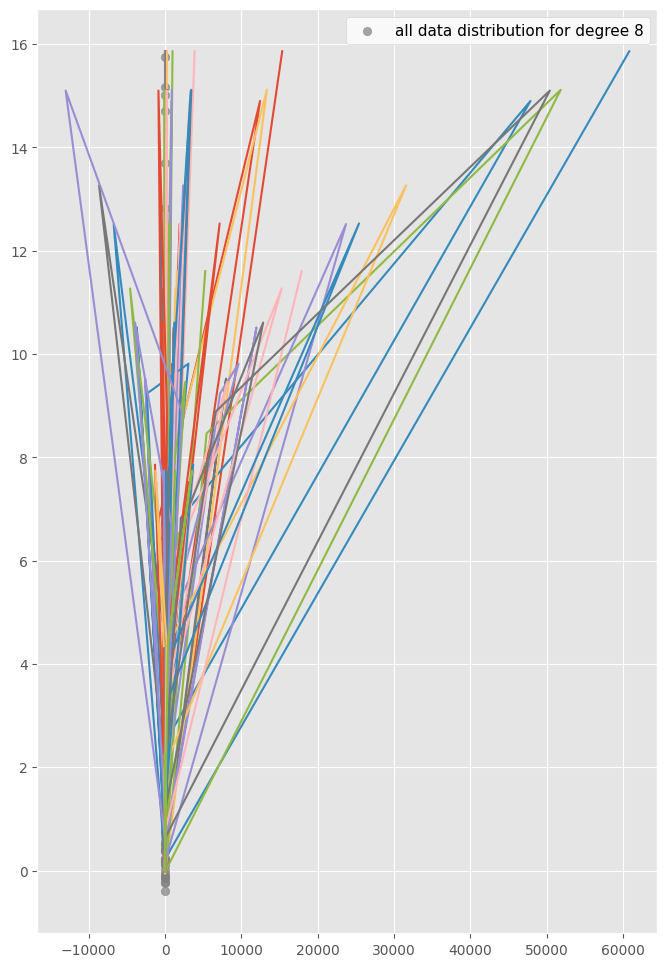

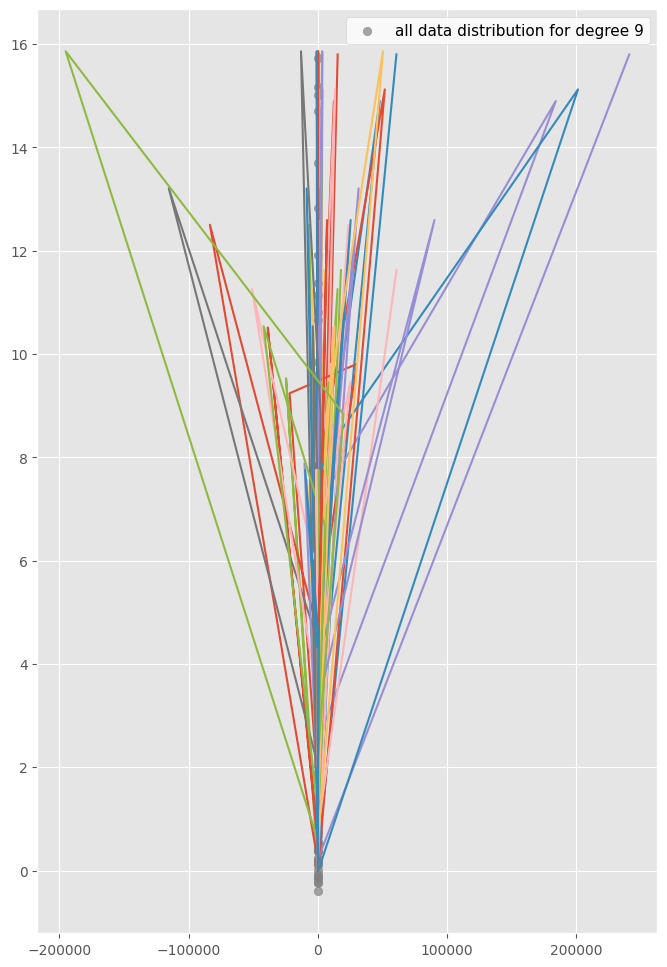

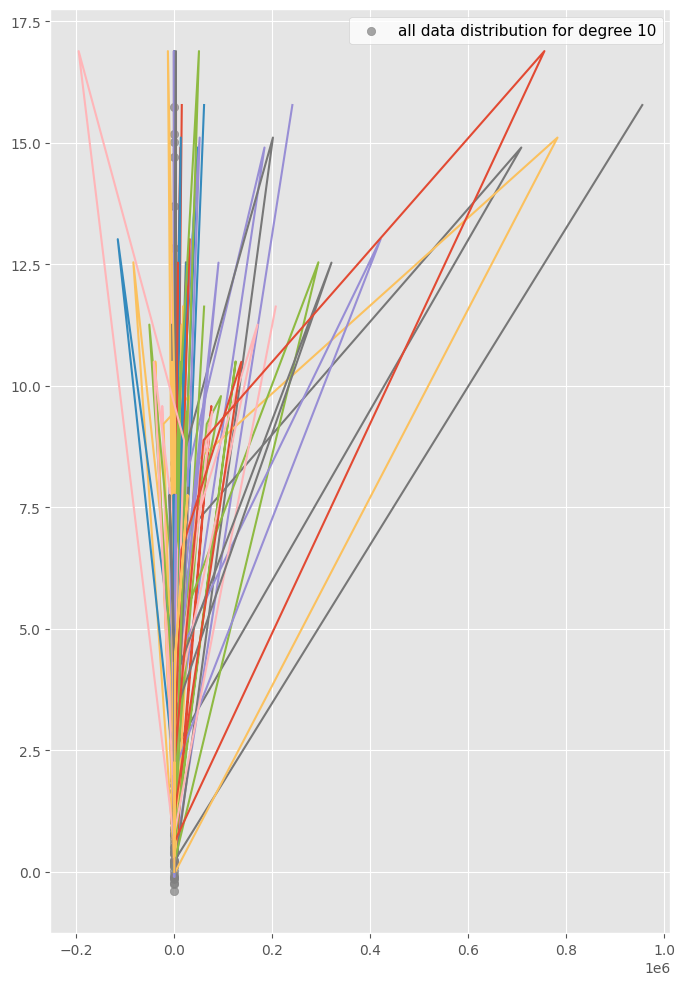

[18.8182891   0.06407808  0.06555379  0.06663366  0.06650603  0.06750518
  0.06928353  0.07020692  0.07533371  0.09451922] [0.3477782  0.00136939 0.001733   0.00195115 0.00175617 0.00215382
 0.00290083 0.00333893 0.00444601 0.00766818]


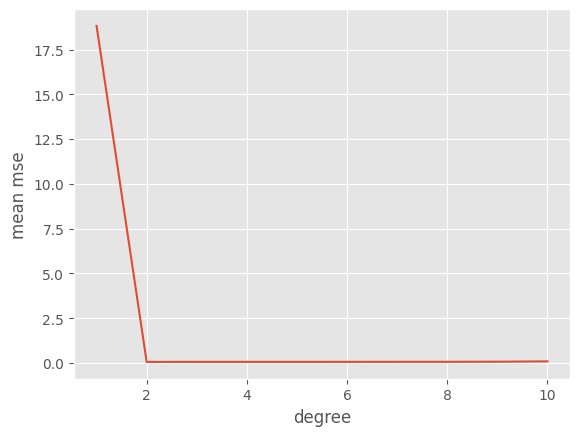

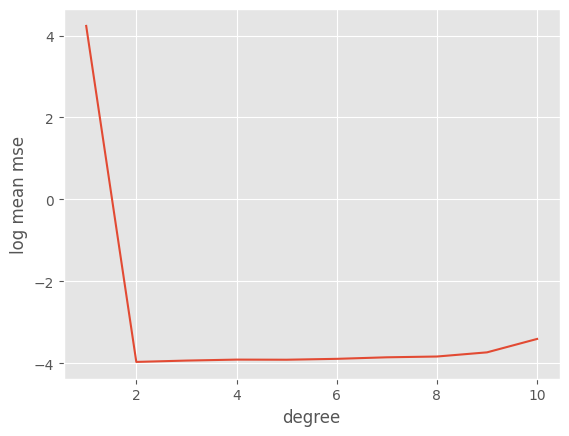

In [55]:
# BEGIN SOLUTION

# END SOLUTION

## Q4) Bootstrap the following dataset (`n = 1000`) to obtain median and 95% CI (Confidence interval)for parameter estimates (slope and intercept) summarizing the relationship between `x` and `y_measured.` What happens with median parameter estimates when you examine `y` instead?

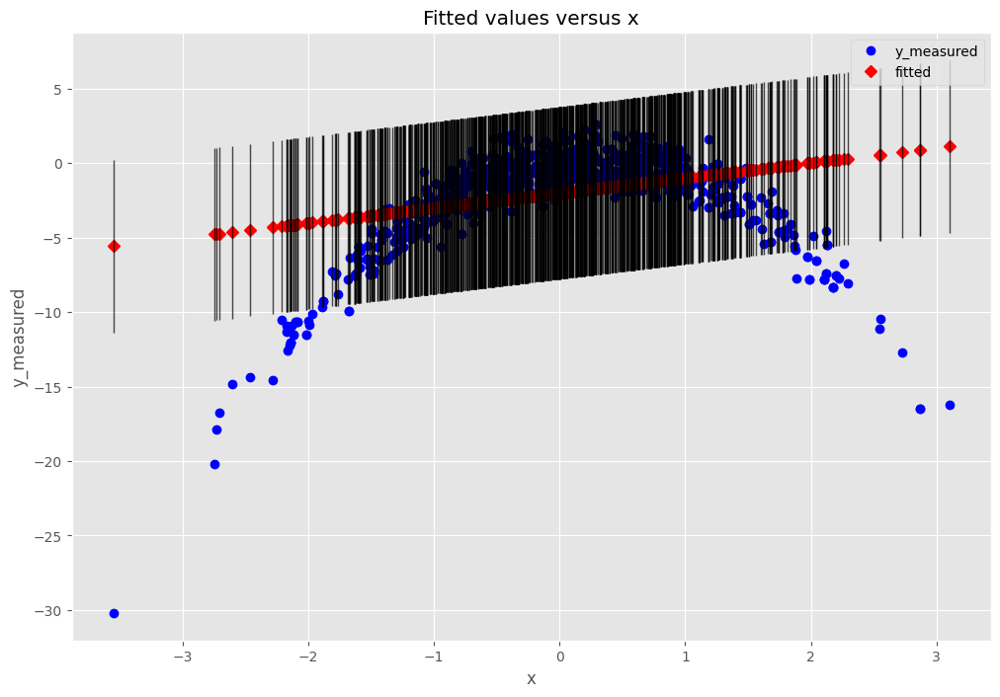

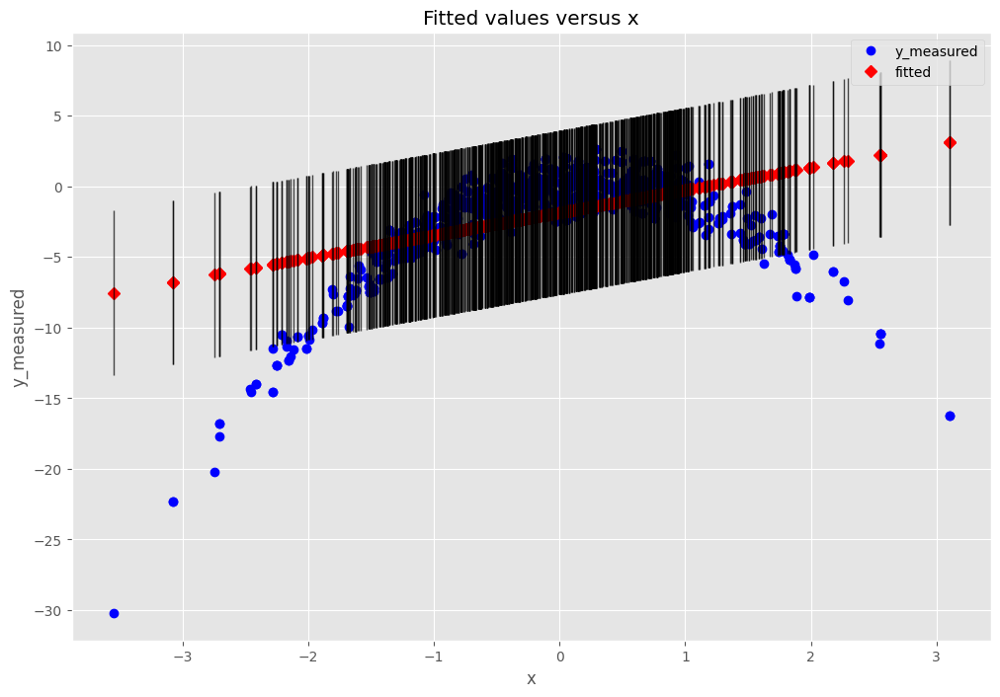

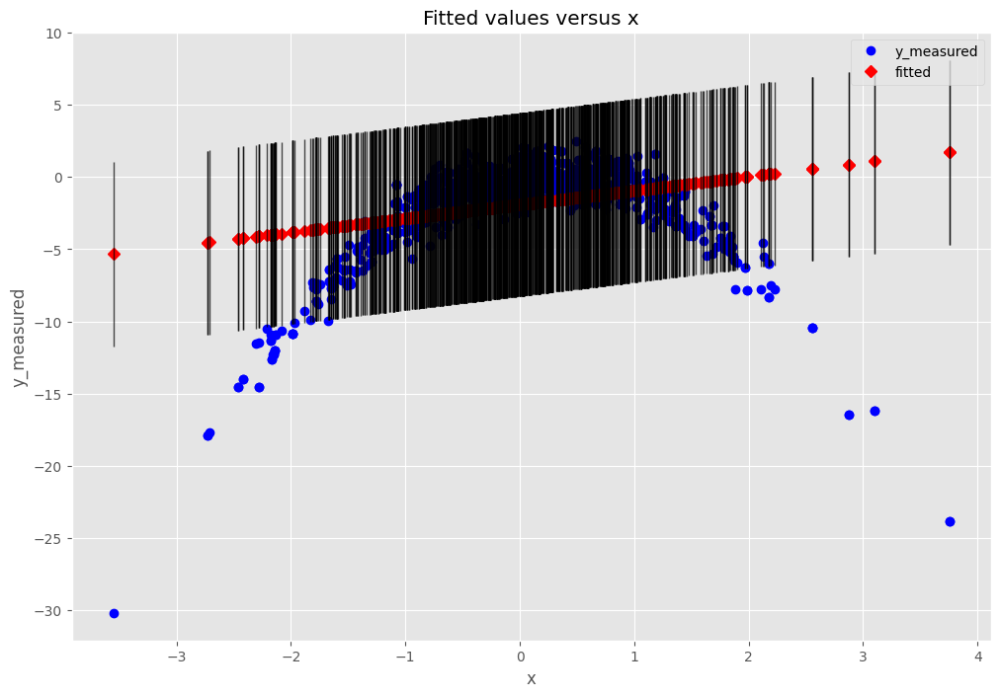

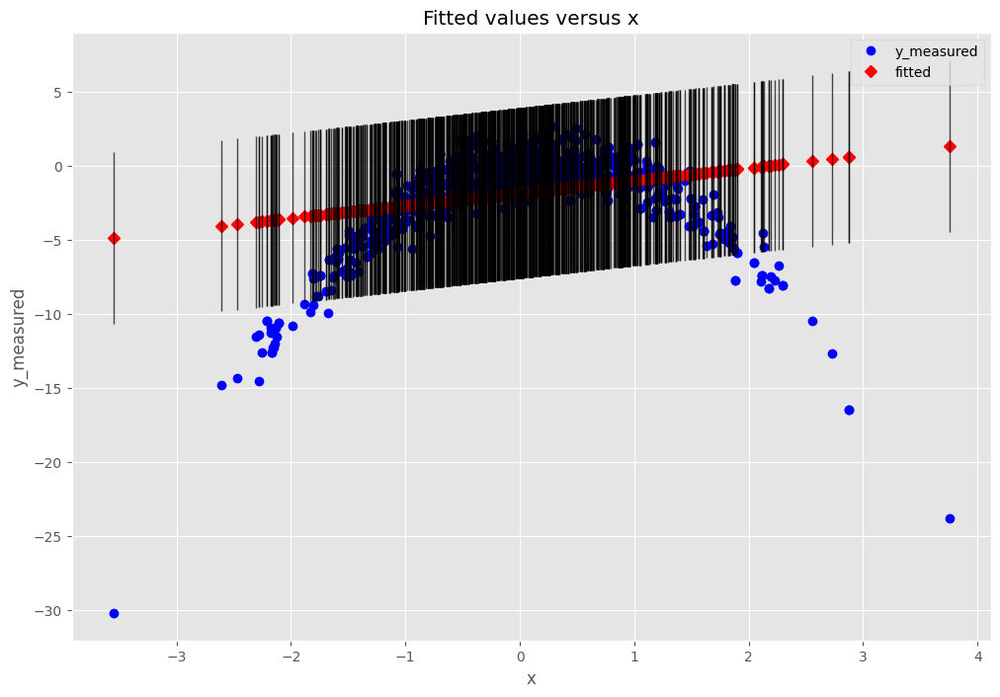

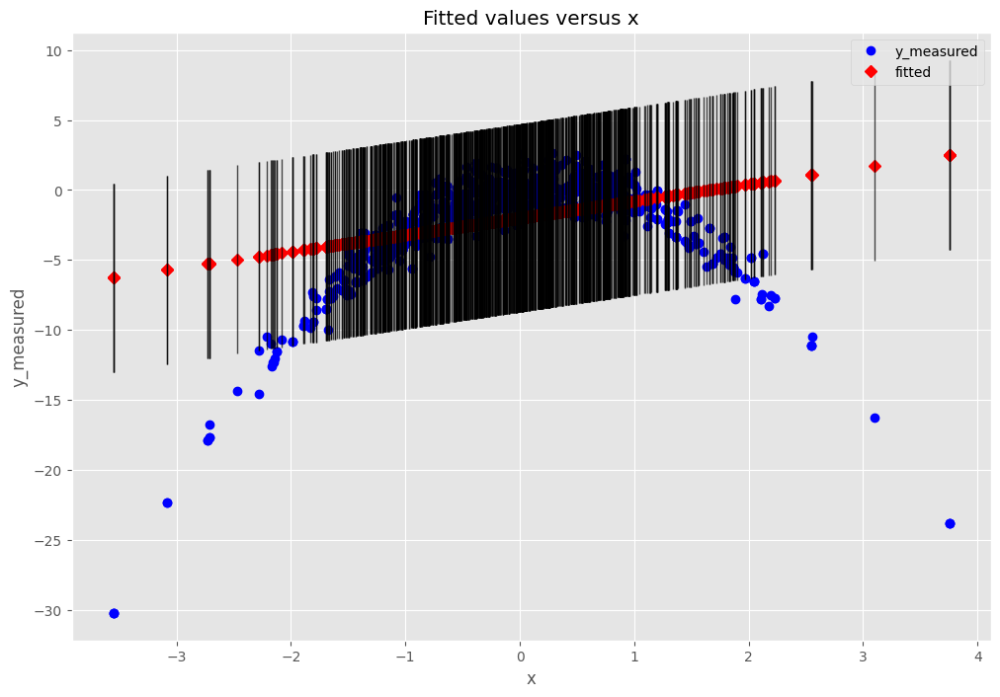

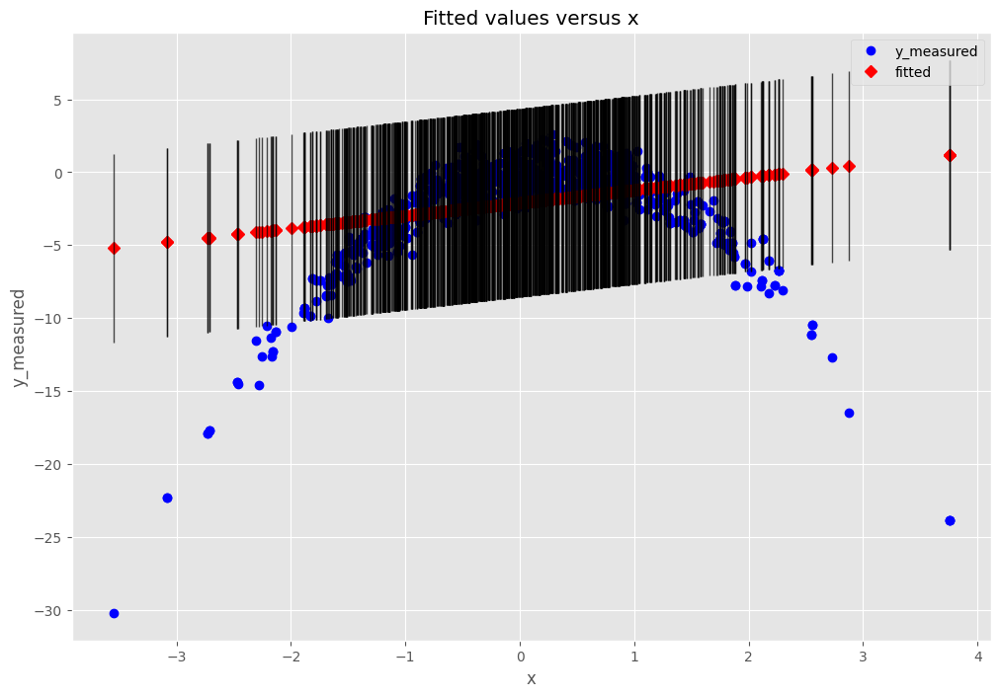

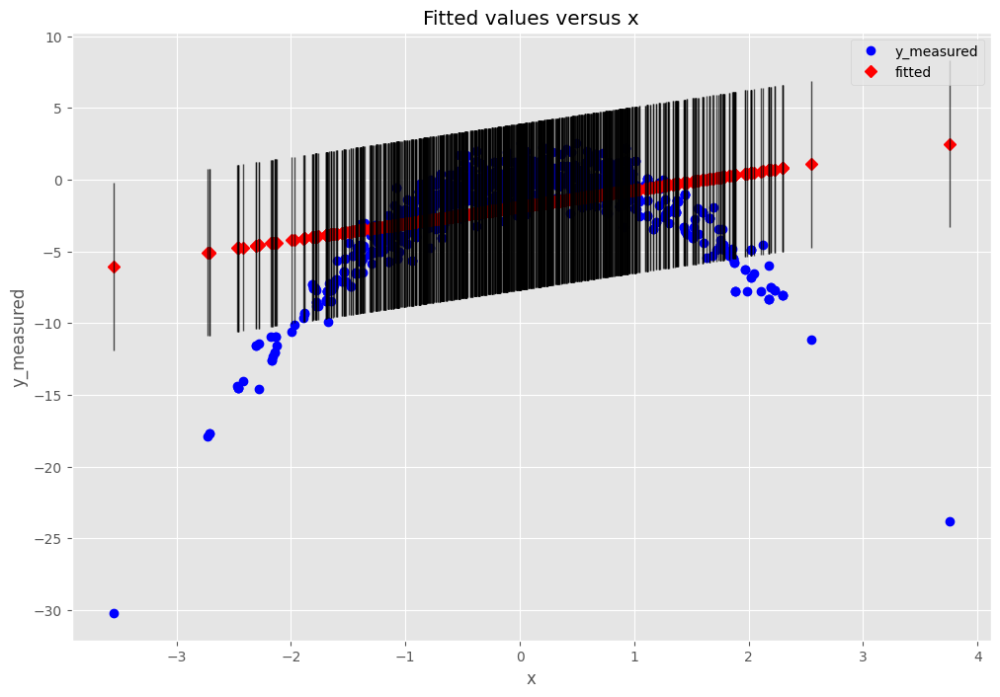

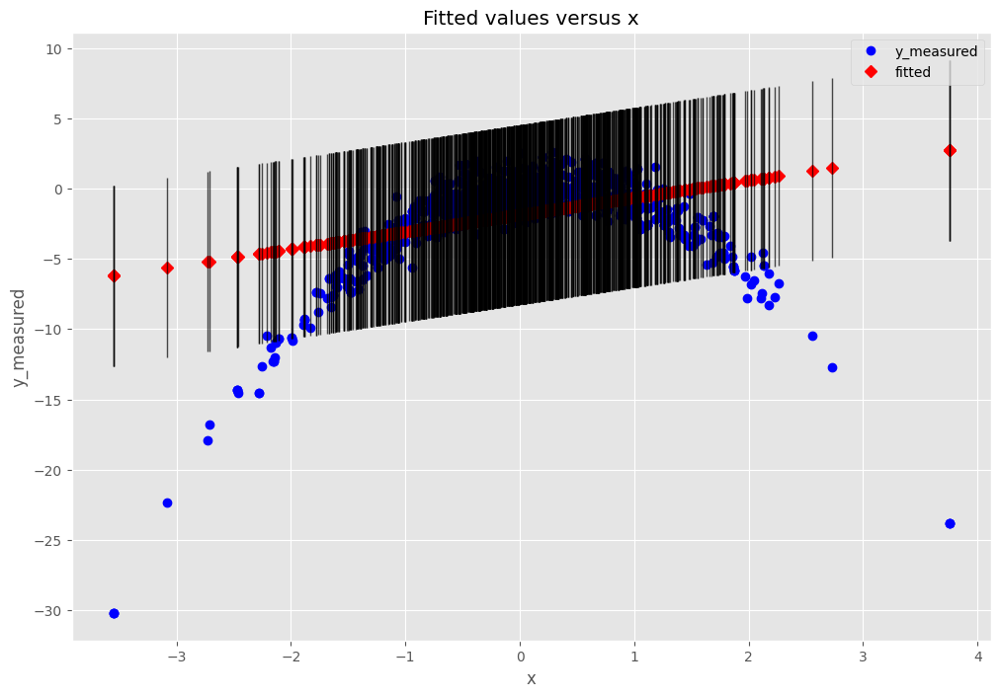

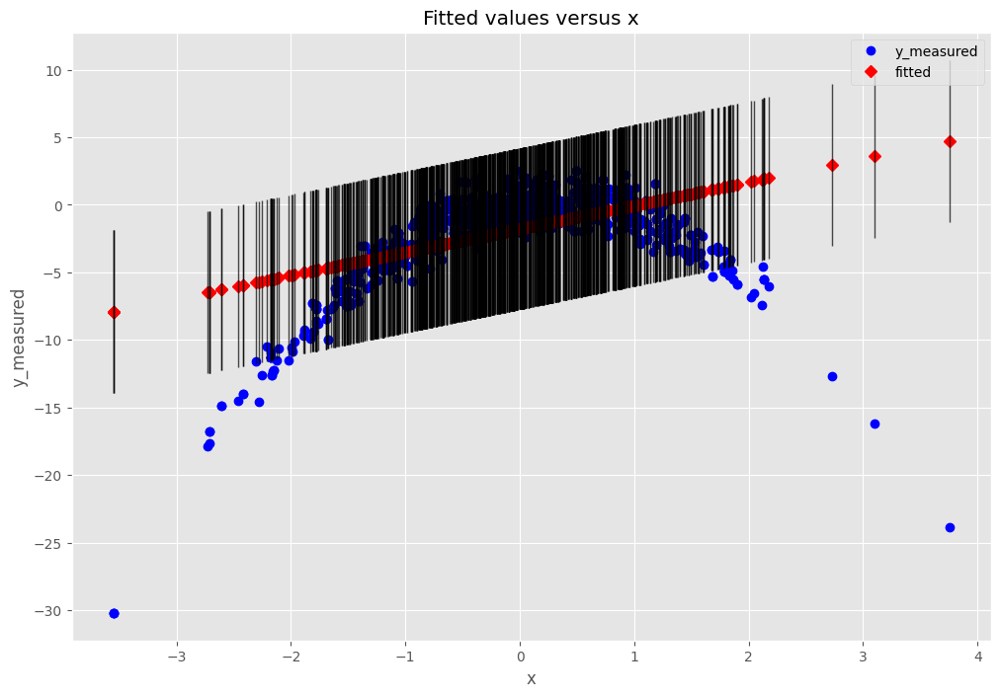

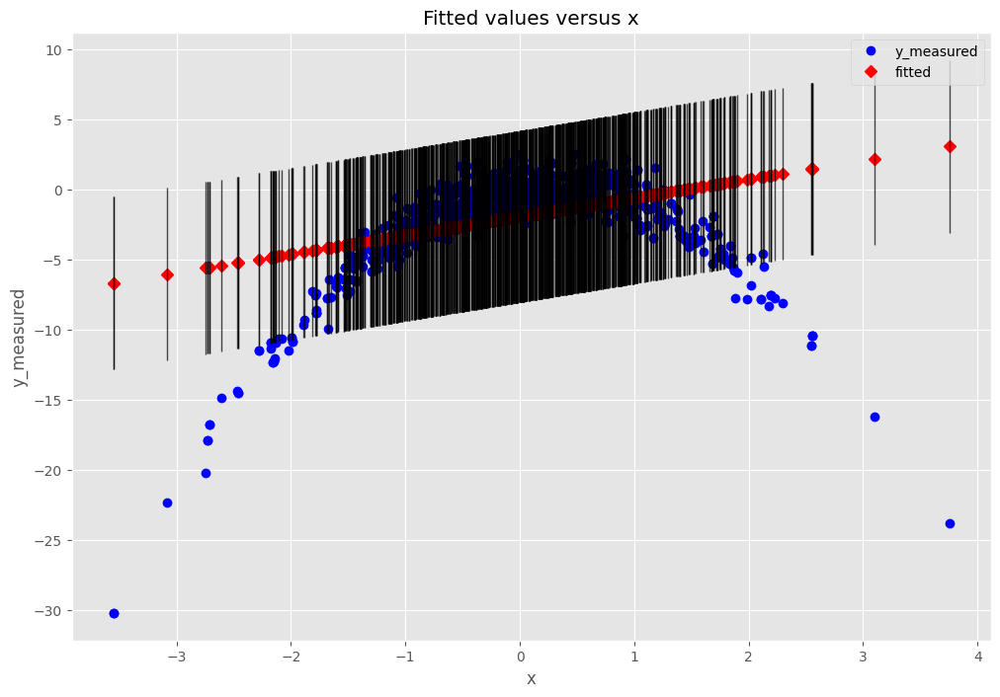

In [61]:
import numpy as np
from numpy.random import default_rng
import scipy.stats as stats

rng = default_rng(seed=1)
nobs = 1000
x = rng.normal(size=nobs)
y = x - 2 * x**2
y_measured = y + rng.normal(size=nobs)

# BEGIN SOLUTION
# END SOLUTION


Provide your answer in this Markdown cell

## Q5) We will predict the number of applications received using the other variables in the **College dataset.** Please load the relevant dataset first.


**Importing Libraries:**

In [75]:
#IMPORT LIBRARIES

**Loading dataset:**

In [76]:
#READ AUTO.CSV DATASET

In [77]:
#PERFORM PRE PROCESSING OF DATA IF REQUIRED ( OBSERVE THE DATASET AND ITS VALUES CAREFULLY)

(397, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           397 non-null    float64
 1   cylinders     397 non-null    int64  
 2   displacement  397 non-null    float64
 3   horsepower    397 non-null    object 
 4   weight        397 non-null    int64  
 5   acceleration  397 non-null    float64
 6   year          397 non-null    int64  
 7   origin        397 non-null    int64  
 8   name          397 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.0+ KB
<class 'pandas.core.frame.DataFrame'>
Index: 392 entries, 0 to 396
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    in

### a) Split the data set into a training set and a test set.

In [78]:
# BEGIN SOLUTION
# END SOLUTION

### b) Fit a linear model using least squares on the training set, and report the test error obtained.
Link to linear model: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html


In [80]:
#BEGIN SOLUTION

# END SOLUTION

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.825
Model:                            OLS   Adj. R-squared:                  0.820
Method:                 Least Squares   F-statistic:                     178.7
Date:                Thu, 02 Nov 2023   Prob (F-statistic):           1.09e-96
Time:                        01:03:57   Log-Likelihood:                -713.15
No. Observations:                 274   AIC:                             1442.
Df Residuals:                     266   BIC:                             1471.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          -18.3282      5.554     -3.300   

11.569797030216787

### c) Fit a ridge regression model on the training set, with $\lambda$ chosen by cross-validation. Report the test error obtained.

Link to ridge regresion : https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

In [ ]:
#BEGIN SOLUTION

# END SOLUTION

### d) Fit a lasso model on the training set, with $\lambda$ chosen by cross-validation. Report the test error obtained, along with the number of non-zero coefficient estimates.
 Link to lasso :https://scikit-learn.org/0.15/modules/generated/sklearn.linear_model.Lasso.html

In [ ]:
#BEGIN SOLUTION

# END SOLUTION